## Análisis PSI con PyGMTSAR

El paquete de PyGMTSAR para procesamiento interferométrico fue diseñado por [Alexey Pechnikov](https://www.linkedin.com/in/alexey-pechnikov/). Este paquete o librería para Python usa GMTSAR para procesamiento interferométrico de imágenes Sentinel 1. En este ejercicio usaremos procesamiento PSI para establecer la posibilidad de obtener deformación a escala de estructura en el área de deformación activa de Manrique.

Jhon Restrepo y Johnny Vega (2026). Basados en el paquete y Jupyter Notebooks de Alexey Pechnikov.

## Instalación del paquete en Google Colab y cargar módulos de python y área de estudio

Instalar PyGMTSAR y requerimientos de GMTSAR (incluyendo SNAPHU)

In [ ]:
import platform, sys, os
if 'google.colab' in sys.modules:

    # install PyGMTSAR stable version from PyPI
    !{sys.executable} -m pip install -q pygmtsar
    # alternatively, nstall PyGMTSAR development version from GitHub
    #!{sys.executable} -m pip install -Uq git+https://github.com/mobigroup/gmtsar.git@pygmtsar2#subdirectory=pygmtsar
    # use PyGMTSAR Google Colab installation script to install binary dependencies
    # script URL: https://github.com/AlexeyPechnikov/pygmtsar/blob/pygmtsar2/pygmtsar/pygmtsar/data/google_colab.sh
    import importlib.resources as resources
    with resources.as_file(resources.files('pygmtsar.data') / 'google_colab.sh') as google_colab_script_filename:
        !sh {google_colab_script_filename}

# specify GMTSAR installation path
PATH = os.environ['PATH']
if PATH.find('GMTSAR') == -1:
    PATH = os.environ['PATH'] + ':/usr/local/GMTSAR/bin/'
    %env PATH {PATH}

# display PyGMTSAR version
from pygmtsar import __version__
__version__

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 61.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 133.0/133.0 kB 9.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.4/72.4 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 61.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 57.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 322.4/322.4 kB 20.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 94.5 MB/s eta 0:00:00
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)




update-alternatives: using /usr/bin/gcc-9 to provide /usr/bin/gcc (gcc) in auto mode
There is 1 choice for the alternative gcc (providing /usr/bin/gcc).

  Selection    Path            Priority   Status
-------------------------------------------------------

'2025.4.8.post1'

In [ ]:
import xarray as xr
import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
from dask.distributed import Client
import dask
import json
import warnings
import logging
from pygmtsar import S1, Stack, tqdm_dask, ASF, Tiles
# supress warning "Detected different `run_spec` for key"
logging.getLogger("distributed.scheduler").setLevel(logging.ERROR)

In [ ]:
from contextlib import contextmanager
# plotting modules
import matplotlib.pyplot as plt
import matplotlib
@contextmanager
def mpl_settings(settings):
    original_settings = {k: plt.rcParams[k] for k in settings}
    plt.rcParams.update(settings)
    yield
    plt.rcParams.update(original_settings)
plt.rcParams['figure.figsize'] = [12, 4]
plt.rcParams['figure.dpi'] = 100
plt.rcParams['figure.titlesize'] = 24
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12
%matplotlib inline

Se seleccionan las imágenes que tienen cobertura en el área de estudio, en la ventana temporal deseada. Para ello, se debe importar el área de Manrique creada previamente en QGIS

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

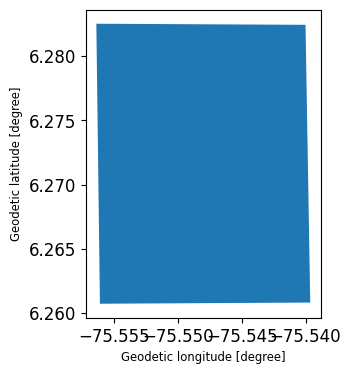

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# Project folder in Google Drive
PROJECT_DIR = '/content/drive/MyDrive/Tutoriales_InSAR/Deformación_estructura_DAGRD'
AOI_FILE = f'{PROJECT_DIR}/Área_Manrique.geojson'
ADA_FILE = f'{PROJECT_DIR}/ADAs_Medellin_por_sector.gpkg'

AOI = gpd.read_file(AOI_FILE).to_crs(4326)
AOI_WKT = AOI.geometry.union_all().wkt
AOI.plot()

## Descargar y extraer datasets

In [ ]:
import asf_search as asf

START = '2024-10-01'
END = '2026-10-10'

results = asf.geo_search(
    platform=asf.PLATFORM.SENTINEL1,
    processingLevel=asf.PRODUCT_TYPE.SLC,
    beamMode=asf.BEAMMODE.IW,
    intersectsWith=AOI_WKT,
    start=START,
    end=END,
)
scenes_df = pd.DataFrame([r.properties for r in results])
scenes_df['date'] = pd.to_datetime(scenes_df['startTime']).dt.date

# Number of acquisitions per orbit direction, path and frame
scenes_df.groupby(['flightDirection', 'pathNumber', 'frameNumber']).size()

["'type': 'GEOMETRY_SIMPLIFICATION': 'report': 'Shape Simplified: shape of 6 simplified to 4 with proximity threshold of 0.0004'", "'type': 'REVERSE': 'report': Reversed polygon winding order"]


flightDirection  pathNumber  frameNumber
ASCENDING        150         1197             2
                             1198             7
                             1200            24
                             1201             1
                             1203             2
DESCENDING       42          571              1
                 142         569              1
                             571            109
dtype: int64

Selección de escenas y órbitas, de acuerdo con aquellas que tienen mayor cantidad de datos. También, se debe tener en cuenta que para Manrique, ubicado en el noreste de Medellín, la órbita descendente muestra una correlación más fuerte con los daños estructurales reportados. Según Vega et al., (2026), esta órbita tiene una geometría de observación más favorable.

In [ ]:
# Choose one orbit direction and path from the table above
FLIGHT_DIRECTION = 'DESCENDING'
PATH_NUMBER = 142      # replace with the path from the table with the most acquisitions
FRAME_NUMBER = 571     # replace with the frame from the table

sel = scenes_df[(scenes_df.flightDirection == FLIGHT_DIRECTION) &
                (scenes_df.pathNumber == PATH_NUMBER)].sort_values('date')
SCENES = sel['sceneName'].tolist()
print(len(SCENES), 'scenes from', sel.date.min(), 'to', sel.date.max())

POLARIZATION = 'VV'

110 scenes from 2024-10-10 to 2026-10-07


La selección de la referencia se hace para elegir la imagen que servirá para coregistrar las otras. En PSI, la referencia no es necesario que sea la imagen de la primera fecha

In [ ]:
REFERENCE    = '2025-08-18'
WORKDIR      = 'raw'+REFERENCE
DATADIR      = 'data'+REFERENCE
BASEDAYS     = 36
BASEMETERS   = 150

Para el área de estudio creada, se observa qué subswaths y bursts cubren la zona:

In [ ]:
bursts = asf.geo_search(
    dataset=asf.DATASET.SLC_BURST,
    intersectsWith=AOI_WKT,
    start=START, end=END,
    polarization='VV',
    relativeOrbit=142,
    flightDirection='DESCENDING',
)
bursts_df = pd.DataFrame([r.properties['burst'] for r in bursts])
bursts_df[['fullBurstID', 'subswath']].value_counts()

["'type': 'GEOMETRY_SIMPLIFICATION': 'report': 'Shape Simplified: shape of 6 simplified to 4 with proximity threshold of 0.0004'", "'type': 'REVERSE': 'report': Reversed polygon winding order"]
ERROR:asf_search:The asf-search module ecountered an error with CMR,and the following message was automatically reported to ASF:

"
message
"If you have any questions email uso@asf.alaska.edu
ERROR:asf_search:The asf-search module ecountered an error with CMR,and the following message was automatically reported to ASF:

"
message
"If you have any questions email uso@asf.alaska.edu
ERROR:asf_search:Results may be incomplete due to a search error. See ASF_LOGGER logging for more details.


,,count
fullBurstID,subswath,
142_303898_IW1,IW1,105
142_303897_IW1,IW1,103


In [ ]:
BURST_IDS = ['142_303897_IW1', '142_303898_IW1']
PLATFORMS = ['SENTINEL-1A']
REFERENCE = '2025-08-18'

# Search in two time windows to avoid incomplete CMR result pages
windows = [(START, '2025-08-31'), ('2025-09-01', END)]
bursts = []
for s, e in windows:
    bursts += asf.geo_search(
        dataset=asf.DATASET.SLC_BURST,
        intersectsWith=AOI_WKT,
        start=s, end=e,
        polarization='VV',
        relativeOrbit=142,
        flightDirection='DESCENDING',
    )

bursts_df = pd.DataFrame([{
    'name': r.properties['fileID'],
    'fullBurstID': r.properties['burst']['fullBurstID'],
    'platform': r.properties['platform'].upper(),
    'date': pd.to_datetime(r.properties['startTime']).normalize().tz_localize(None),
} for r in bursts])

# Keep both bursts, selected platform(s), and dates on the 12-day grid of the reference
ref = pd.Timestamp(REFERENCE)
on_grid = ((bursts_df.date - ref).dt.days % 12) == 0
cand = bursts_df[bursts_df.fullBurstID.isin(BURST_IDS) &
                 bursts_df.platform.isin(PLATFORMS) &
                 on_grid]

# Keep only dates where all bursts are available
n_per_date = cand.groupby('date').fullBurstID.nunique()
complete_dates = n_per_date[n_per_date == len(BURST_IDS)].index
sel_bursts = cand[cand.date.isin(complete_dates)].sort_values(['date', 'fullBurstID'])

BURSTS = [n if n.endswith('-BURST') else n + '-BURST' for n in sel_bursts.name]
sel_dates = sel_bursts.date.drop_duplicates()

print(len(BURSTS), 'bursts for', len(sel_dates), 'dates,', sel_dates.min().date(), 'to', sel_dates.max().date())
print('Max gap (days):', sel_dates.diff().dt.days.max())
print('Reference included:', ref in set(sel_dates))
sel_bursts.groupby('fullBurstID').size()

["'type': 'GEOMETRY_SIMPLIFICATION': 'report': 'Shape Simplified: shape of 6 simplified to 4 with proximity threshold of 0.0004'", "'type': 'REVERSE': 'report': Reversed polygon winding order"]
["'type': 'GEOMETRY_SIMPLIFICATION': 'report': 'Shape Simplified: shape of 6 simplified to 4 with proximity threshold of 0.0004'", "'type': 'REVERSE': 'report': Reversed polygon winding order"]
ERROR:asf_search:The asf-search module ecountered an error with CMR,and the following message was automatically reported to ASF:

"
message
"If you have any questions email uso@asf.alaska.edu
ERROR:asf_search:The asf-search module ecountered an error with CMR,and the following message was automatically reported to ASF:

"
message
"If you have any questions email uso@asf.alaska.edu
ERROR:asf_search:Results may be incomplete due to a search error. See ASF_LOGGER logging for more details.


90 bursts for 45 dates, 2024-10-10 to 2026-04-03
Max gap (days): 24.0
Reference included: True


,0
fullBurstID,
142_303897_IW1,45
142_303898_IW1,45


## Ingresar usuario y contraseña de ASF y descargar datos, órbitas y DEM

Si el directorio de datos está vacío o no existe, tendrá que descargar las escenas de Sentinel-1 desde el repositorio del Alaska Satellite Facility (ASF). Use sus credenciales de Earthdata Login. Si no tiene una cuenta de Earthdata Login, puede crearla en https://urs.earthdata.nasa.gov/users/new

También puede usar escenas SLC ya existentes almacenadas en su Google Drive, o copiarlas mediante un enlace público directo de iCloud Drive.

In [ ]:
# Set these variables to None and you will be prompted to enter your username and password below.
asf_username = 'drestrepo_j'
asf_password = 'Pendejo2406-'

In [ ]:
# TEST_MODE = True downloads only the reference date and its neighbor (ÚTIL PARA LA CLASE/TALLER)
TEST_MODE = False

if TEST_MODE:
    i = list(sel_dates).index(ref)
    demo_dates = sel_dates.iloc[i:i+2]
    BURSTS_TO_DOWNLOAD = [b for b, d in zip(BURSTS, sel_bursts.date) if d in set(demo_dates)]
else:
    BURSTS_TO_DOWNLOAD = BURSTS

print(len(BURSTS_TO_DOWNLOAD), 'bursts to download')

asf_client = ASF(asf_username, asf_password)
asf_client.download(DATADIR, BURSTS_TO_DOWNLOAD)

90 bursts to download


ASF Downloading Bursts Catalog:   0%|          | 0/1 [00:00<?, ?it/s]

ASF Downloading Sentinel-1 SLC Bursts:   0%|          | 0/90 [00:00<?, ?it/s]

,burst_or_scene
0,S1_303897_IW1_20241010T105120_VV_6A5B-BURST
1,S1_303898_IW1_20241010T105122_VV_6A5B-BURST
2,S1_303897_IW1_20241022T105119_VV_696F-BURST
3,S1_303898_IW1_20241022T105122_VV_696F-BURST
4,S1_303897_IW1_20241103T105119_VV_7000-BURST
...,...
85,S1_303898_IW1_20260226T105104_VV_0F7D-BURST
86,S1_303897_IW1_20260322T105101_VV_A09A-BURST
87,S1_303898_IW1_20260322T105104_VV_A09A-BURST
88,S1_303897_IW1_20260403T105101_VV_F92D-BURST


In [ ]:
# scan the data directory for SLC scenes and download missed orbits
S1.download_orbits(DATADIR, S1.scan_slc(DATADIR))

NOTE: Found multiple scenes for a single day, use function Stack.reframe() to stitch the scenes


,orbit
0,S1A_OPER_AUX_POEORB_OPOD_20241030T070550_V2024...
1,S1A_OPER_AUX_POEORB_OPOD_20241111T070613_V2024...
2,S1A_OPER_AUX_POEORB_OPOD_20241123T070558_V2024...
3,S1A_OPER_AUX_POEORB_OPOD_20241205T070604_V2024...
4,S1A_OPER_AUX_POEORB_OPOD_20241217T070615_V2024...
5,S1A_OPER_AUX_POEORB_OPOD_20241229T070554_V2024...
6,S1A_OPER_AUX_POEORB_OPOD_20250110T070616_V2024...
7,S1A_OPER_AUX_POEORB_OPOD_20250122T070623_V2025...
8,S1A_OPER_AUX_POEORB_OPOD_20250203T070705_V2025...
9,S1A_OPER_AUX_POEORB_OPOD_20250215T070617_V2025...


Se descarga el DEM de Copernicus para la zona de estudio. Este permite remover la fase topográfica del análisis de InSAR

Tiles Parallel Downloading:   0%|          | 0/1 [00:00<?, ?it/s]

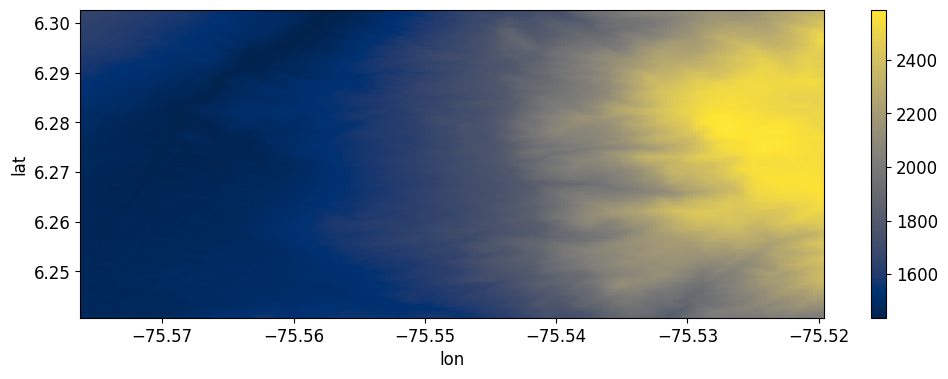

In [ ]:
DEM = f'{DATADIR}/dem.nc'

# Buffer the AOI so the DEM fully covers the processed area (radar geometry and steep slopes)
AOI_DEM = AOI.buffer(0.02)

# download Copernicus Global DEM 1 arc-second
Tiles().download_dem(AOI_DEM, filename=DEM).plot.imshow(cmap='cividis')

## Ejecutar un clúster local de Dask

Inicia un clúster de Dask para cómputo multinúcleo local y distribuido. Esto permite procesar conjuntos de datos SLC de Sentinel-1 del orden de terabytes en un MacBook Air con 16 GB de RAM.

In [ ]:
# Disable HDF5 file locking (avoids BlockingIOError on Colab)
os.environ['HDF5_USE_FILE_LOCKING'] = 'FALSE'
# simple Dask initialization
if 'client' in globals():
    client.close()
# One worker with all the memory, to avoid workers being killed on Colab
client = Client(n_workers=1, threads_per_worker=2, memory_limit='10GB')
client

INFO:distributed.http.proxy:To route to workers diagnostics web server please install jupyter-server-proxy: python -m pip install jupyter-server-proxy
INFO:distributed.nanny:        Start Nanny at: 'tcp://127.0.0.1:45651'
INFO:distributed.core:Starting established connection to tcp://127.0.0.1:57426
INFO:distributed.core:Starting established connection to tcp://127.0.0.1:57436


Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: http://127.0.0.1:8787/status,
Dashboard: http://127.0.0.1:8787/status,Workers: 1
Total threads: 2,Total memory: 9.31 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:39681,Workers: 0
Dashboard: http://127.0.0.1:8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:36227,Total threads: 2
Dashboard: http://127.0.0.1:38357/status,Memory: 9.31 GiB
Nanny: tcp://127.0.0.1:45651,


## Init

Busca de forma recursiva los archivos de medición (.tiff), de anotación (.xml) y de órbita (.EOF) dentro del directorio DATA. Puede tratarse de un directorio con subdirectorios de escenas completas descomprimidas (.SAFE), o simplemente de un directorio con la lista de pares de archivos .tiff y .xml necesarios (posiblemente prefiltrados por órbita, polarización y subswath para ahorrar espacio en disco). Si faltan los archivos de órbita o el DEM, se descargarán automáticamente más adelante.

In [ ]:
scenes = S1.scan_slc(DATADIR)
scenes

NOTE: Found multiple scenes for a single day, use function Stack.reframe() to stitch the scenes


,datetime,orbit,mission,polarization,subswath,datapath,metapath,noisepath,calibpath,orbitpath,geometry
date,,,,,,,,,,,
2024-10-10,2024-10-10 10:51:20,D,S1A,VV,1,data2025-08-18/S1A_IW_SLC__1SDV_20241010T10512...,data2025-08-18/S1A_IW_SLC__1SDV_20241010T10512...,None,None,data2025-08-18/S1A_OPER_AUX_POEORB_OPOD_202410...,"MULTIPOLYGON (((-74.9526 6.3222, -74.99478 6.3..."
2024-10-10,2024-10-10 10:51:22,D,S1A,VV,1,data2025-08-18/S1A_IW_SLC__1SDV_20241010T10512...,data2025-08-18/S1A_IW_SLC__1SDV_20241010T10512...,None,None,data2025-08-18/S1A_OPER_AUX_POEORB_OPOD_202410...,"MULTIPOLYGON (((-74.98588 6.15483, -75.0319 6...."
2024-10-22,2024-10-22 10:51:19,D,S1A,VV,1,data2025-08-18/S1A_IW_SLC__1SDV_20241022T10511...,data2025-08-18/S1A_IW_SLC__1SDV_20241022T10511...,None,None,data2025-08-18/S1A_OPER_AUX_POEORB_OPOD_202411...,"MULTIPOLYGON (((-74.95088 6.32167, -74.99306 6..."
2024-10-22,2024-10-22 10:51:22,D,S1A,VV,1,data2025-08-18/S1A_IW_SLC__1SDV_20241022T10512...,data2025-08-18/S1A_IW_SLC__1SDV_20241022T10512...,None,None,data2025-08-18/S1A_OPER_AUX_POEORB_OPOD_202411...,"MULTIPOLYGON (((-74.98414 6.15442, -75.03016 6..."
2024-11-03,2024-11-03 10:51:19,D,S1A,VV,1,data2025-08-18/S1A_IW_SLC__1SDV_20241103T10511...,data2025-08-18/S1A_IW_SLC__1SDV_20241103T10511...,None,None,data2025-08-18/S1A_OPER_AUX_POEORB_OPOD_202411...,"MULTIPOLYGON (((-74.9519 6.32164, -74.99407 6...."
...,...,...,...,...,...,...,...,...,...,...,...
2026-02-26,2026-02-26 10:51:04,D,S1A,VV,1,data2025-08-18/S1A_IW_SLC__1SDV_20260226T10510...,data2025-08-18/S1A_IW_SLC__1SDV_20260226T10510...,None,None,data2025-08-18/S1A_OPER_AUX_POEORB_OPOD_202603...,"MULTIPOLYGON (((-74.98437 6.15578, -75.03039 6..."
2026-03-22,2026-03-22 10:51:01,D,S1A,VV,1,data2025-08-18/S1A_IW_SLC__1SDV_20260322T10510...,data2025-08-18/S1A_IW_SLC__1SDV_20260322T10510...,None,None,data2025-08-18/S1A_OPER_AUX_POEORB_OPOD_202604...,"MULTIPOLYGON (((-74.95174 6.32326, -74.99392 6..."
2026-03-22,2026-03-22 10:51:04,D,S1A,VV,1,data2025-08-18/S1A_IW_SLC__1SDV_20260322T10510...,data2025-08-18/S1A_IW_SLC__1SDV_20260322T10510...,None,None,data2025-08-18/S1A_OPER_AUX_POEORB_OPOD_202604...,"MULTIPOLYGON (((-74.98497 6.15613, -75.03099 6..."


In [ ]:
if TEST_MODE:
    # Class demo: new stack from the downloaded sample
    psi = Stack(WORKDIR, drop_if_exists=True).set_scenes(scenes).set_reference(REFERENCE)
else:
    # Full processing: same, but only run once to build the checkpoint
    psi = Stack(WORKDIR, drop_if_exists=True).set_scenes(scenes).set_reference(REFERENCE)
psi.to_dataframe()

NOTE: auto set reference scene 2024-10-10. You can change it like Stack.set_reference("2022-01-20")


,datetime,orbit,mission,polarization,subswath,datapath,metapath,noisepath,calibpath,orbitpath,geometry
date,,,,,,,,,,,
2024-10-10,2024-10-10 10:51:20,D,S1A,VV,1,data2025-08-18/S1A_IW_SLC__1SDV_20241010T10512...,data2025-08-18/S1A_IW_SLC__1SDV_20241010T10512...,None,None,data2025-08-18/S1A_OPER_AUX_POEORB_OPOD_202410...,"MULTIPOLYGON (((-74.9526 6.3222, -74.99478 6.3..."
2024-10-10,2024-10-10 10:51:22,D,S1A,VV,1,data2025-08-18/S1A_IW_SLC__1SDV_20241010T10512...,data2025-08-18/S1A_IW_SLC__1SDV_20241010T10512...,None,None,data2025-08-18/S1A_OPER_AUX_POEORB_OPOD_202410...,"MULTIPOLYGON (((-74.98588 6.15483, -75.0319 6...."
2024-10-22,2024-10-22 10:51:19,D,S1A,VV,1,data2025-08-18/S1A_IW_SLC__1SDV_20241022T10511...,data2025-08-18/S1A_IW_SLC__1SDV_20241022T10511...,None,None,data2025-08-18/S1A_OPER_AUX_POEORB_OPOD_202411...,"MULTIPOLYGON (((-74.95088 6.32167, -74.99306 6..."
2024-10-22,2024-10-22 10:51:22,D,S1A,VV,1,data2025-08-18/S1A_IW_SLC__1SDV_20241022T10512...,data2025-08-18/S1A_IW_SLC__1SDV_20241022T10512...,None,None,data2025-08-18/S1A_OPER_AUX_POEORB_OPOD_202411...,"MULTIPOLYGON (((-74.98414 6.15442, -75.03016 6..."
2024-11-03,2024-11-03 10:51:19,D,S1A,VV,1,data2025-08-18/S1A_IW_SLC__1SDV_20241103T10511...,data2025-08-18/S1A_IW_SLC__1SDV_20241103T10511...,None,None,data2025-08-18/S1A_OPER_AUX_POEORB_OPOD_202411...,"MULTIPOLYGON (((-74.9519 6.32164, -74.99407 6...."
...,...,...,...,...,...,...,...,...,...,...,...
2026-02-26,2026-02-26 10:51:04,D,S1A,VV,1,data2025-08-18/S1A_IW_SLC__1SDV_20260226T10510...,data2025-08-18/S1A_IW_SLC__1SDV_20260226T10510...,None,None,data2025-08-18/S1A_OPER_AUX_POEORB_OPOD_202603...,"MULTIPOLYGON (((-74.98437 6.15578, -75.03039 6..."
2026-03-22,2026-03-22 10:51:01,D,S1A,VV,1,data2025-08-18/S1A_IW_SLC__1SDV_20260322T10510...,data2025-08-18/S1A_IW_SLC__1SDV_20260322T10510...,None,None,data2025-08-18/S1A_OPER_AUX_POEORB_OPOD_202604...,"MULTIPOLYGON (((-74.95174 6.32326, -74.99392 6..."
2026-03-22,2026-03-22 10:51:04,D,S1A,VV,1,data2025-08-18/S1A_IW_SLC__1SDV_20260322T10510...,data2025-08-18/S1A_IW_SLC__1SDV_20260322T10510...,None,None,data2025-08-18/S1A_OPER_AUX_POEORB_OPOD_202604...,"MULTIPOLYGON (((-74.98497 6.15613, -75.03099 6..."


Para comprobar que la advertencia no coloca la primera imagen como referencia efectiva:

In [ ]:
psi.reference

'2025-08-18'

### Cargar el DEM

La siguiente función carga el DEM desde un archivo o desde una variable de Xarray, y convierte las alturas al modelo elipsoidal usando la grilla EGM96. Esta conversión es necesaria porque los DEM de uso común entregan alturas ortométricas (referidas al geoide), mientras que la geometría de adquisición del radar se calcula respecto al elipsoide WGS84.

In [ ]:
# define the area of interest (AOI) to speedup the processing
psi.load_dem(DEM, AOI)

Save DEM on WGS84 Ellipsoid:   0%|          | 0/9000000.0 [00:00<?, ?it/s]

INFO:distributed.core:Starting established connection to tcp://127.0.0.1:40620


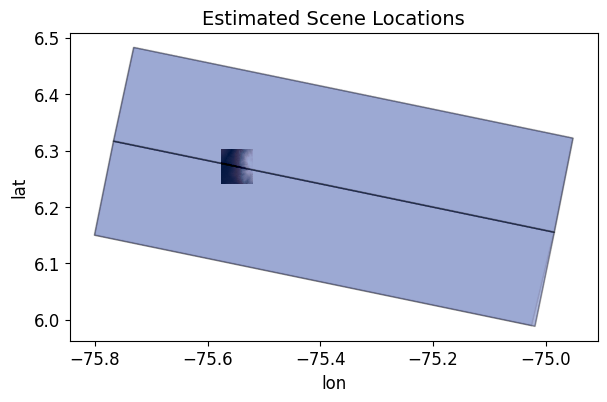

In [ ]:
psi.plot_scenes() # Visualize the location of the scenes selected

## Alinear el grupo de imágenes

In [ ]:
psi.compute_align(debug=True)

Note: sequential joblib processing is applied when "n_jobs" is None or "debug" is True.


Preparing Reference:   0%|          | 0/1 [00:00<?, ?it/s]

DEBUG: argv ['make_s1a_tops', '../data2025-08-18/S1A_IW_SLC__1SDV_20250818T105109_20250818T105112_060589_078953_1FB1.SAFE/annotation/s1a-iw1-slc-vv-20250818t105109-20250818t105112-060589-078953-001.xml', '../data2025-08-18/S1A_IW_SLC__1SDV_20250818T105109_20250818T105112_060589_078953_1FB1.SAFE/measurement/s1a-iw1-slc-vv-20250818t105109-20250818t105112-060589-078953-001.tiff', '2025-08-18_F1', '1']
DEBUG: make_s1a_tops Working on burst  #1
number of points clipped to short int 1 

DEBUG: make_s1a_tops Reading in 2776 lines of info from XML...
Writing 17 lines for orbit...
Writing SLC..Image Size: 21188 X 1456...

DEBUG: argv ['ext_orb_s1a', '2025-08-18_F1.PRM', '../data2025-08-18/S1A_OPER_AUX_POEORB_OPOD_20250907T070542_V20250817T225942_20250819T005942.EOF', '2025-08-18_F1']
DEBUG: ext_orb_s1a Writing 281 lines of precise orbit for the LED file...



Aligning Repeat:   0%|          | 0/44 [00:00<?, ?it/s]

Streaming output truncated to the last 5000 lines.
 [ -75.56458333    6.26902778 1494.73022461]
 [ -75.56125       6.26902778 1507.42077637]
 [ -75.55791667    6.26902778 1541.67553711]
 [ -75.55458333    6.26902778 1591.38769531]
 [ -75.55125       6.26902778 1650.37060547]
 [ -75.54791667    6.26902778 1716.94067383]
 [ -75.54458333    6.26902778 1787.43591309]
 [ -75.54125       6.26902778 1912.97570801]
 [ -75.53791667    6.26902778 2008.80993652]
 [ -75.53458333    6.26902778 2105.99780273]
 [ -75.53125       6.26902778 2290.97558594]
 [ -75.52791667    6.26902778 2417.54589844]
 [ -75.52458333    6.26902778 2557.84082031]
 [ -75.52125       6.26902778 2583.28027344]
 [ -75.57458333    6.27236111 1495.05810547]
 [ -75.57125       6.27236111 1484.84155273]
 [ -75.56791667    6.27236111 1479.84399414]
 [ -75.56458333    6.27236111 1486.51806641]
 [ -75.56125       6.27236111 1504.57897949]
 [ -75.55791667    6.27236111 1547.92895508]
 [ -75.55458333    6.27236111 1598.26452637]
 [ -

Support for third party widgets will remain active for the duration of the session. To disable support:

In [ ]:
from google.colab import output
output.disable_custom_widget_manager()

## Línea base para PSI

In [ ]:
baseline_pairs = psi.sbas_pairs(days=BASEDAYS, meters=BASEMETERS)
baseline_pairs

,ref,rep,ref_baseline,rep_baseline,pair,baseline,duration,rel
0,2024-10-10,2024-10-22,137.15,-10.58,2024-10-10 2024-10-22,-147.73,12,NaT
1,2024-10-10,2024-11-03,137.15,67.07,2024-10-10 2024-11-03,-70.08,24,NaT
2,2024-10-10,2024-11-15,137.15,49.26,2024-10-10 2024-11-15,-87.89,36,NaT
3,2024-10-22,2024-11-03,-10.58,67.07,2024-10-22 2024-11-03,77.65,12,NaT
4,2024-10-22,2024-11-15,-10.58,49.26,2024-10-22 2024-11-15,59.84,24,NaT
...,...,...,...,...,...,...,...,...
114,2026-02-14,2026-02-26,-19.75,-22.62,2026-02-14 2026-02-26,-2.87,12,NaT
115,2026-02-14,2026-03-22,-19.75,38.30,2026-02-14 2026-03-22,58.05,36,NaT
116,2026-02-26,2026-03-22,-22.62,38.30,2026-02-26 2026-03-22,60.92,24,NaT
117,2026-02-26,2026-04-03,-22.62,5.40,2026-02-26 2026-04-03,28.02,36,NaT


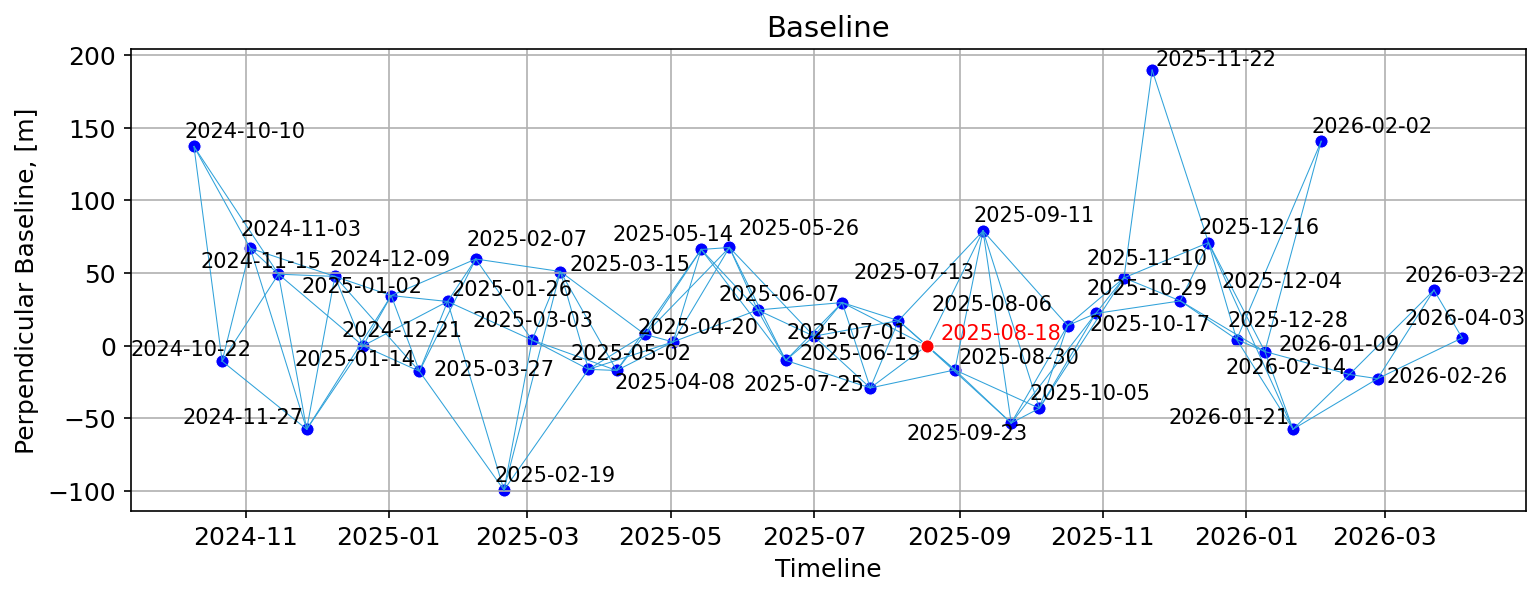

In [ ]:
with mpl_settings({'figure.dpi': 150}):
    psi.plot_baseline(baseline_pairs)
plt.savefig('Baseline.jpg')

## Geocodificación

In [ ]:
# use 15m coordinates grid, better for psi analysis
psi.compute_geocode(15)

Radar Transform Computing:   0%|          | 0/1 [00:00<?, ?it/s]

Radar Transform Saving:   0%|          | 0/9000000.0 [00:00<?, ?it/s]

Radar Transform Indexing:   0%|          | 0/9000000.0 [00:00<?, ?it/s]

Radar Inverse Transform Computing:   0%|          | 0/9000000.0 [00:00<?, ?it/s]

Satellite Look Vector Computing:   0%|          | 0/9000000.0 [00:00<?, ?it/s]

In [ ]:
# Step done to save the checkpoint

psi.dump()

NOTE: save state to file raw2025-08-18/stack.pickle


In [ ]:
!du -sh {WORKDIR} {DATADIR}
print('DEM file:', psi.dem_filename)
psi.to_dataframe()[['datapath', 'orbitpath']].head()

5.2G	raw2025-08-18
11G	data2025-08-18
DEM file: raw2025-08-18/DEM_WGS84.nc


,datapath,orbitpath
date,,
2024-10-10,[data2025-08-18/S1A_IW_SLC__1SDV_20241010T1051...,data2025-08-18/S1A_OPER_AUX_POEORB_OPOD_202410...
2024-10-22,[data2025-08-18/S1A_IW_SLC__1SDV_20241022T1051...,data2025-08-18/S1A_OPER_AUX_POEORB_OPOD_202411...
2024-11-03,[data2025-08-18/S1A_IW_SLC__1SDV_20241103T1051...,data2025-08-18/S1A_OPER_AUX_POEORB_OPOD_202411...
2024-11-15,[data2025-08-18/S1A_IW_SLC__1SDV_20241115T1051...,data2025-08-18/S1A_OPER_AUX_POEORB_OPOD_202412...
2024-11-27,[data2025-08-18/S1A_IW_SLC__1SDV_20241127T1051...,data2025-08-18/S1A_OPER_AUX_POEORB_OPOD_202412...


In [ ]:
CHECKPOINT = f'/content/drive/MyDrive/Tutoriales_InSAR/Deformación_estructura_DAGRD/checkpoint_{REFERENCE}.tar'
!tar -cf {CHECKPOINT} {WORKDIR}
!ls -lh {CHECKPOINT}

-rw------- 1 root root 5.2G Oct 13 04:06 /content/drive/MyDrive/Tutoriales_InSAR/Deformación_estructura_DAGRD/checkpoint_2025-08-18.tar


### Restaurar checkpoint para evitar demora en procesamiento de los pasos anteriores

In [ ]:
CHECKPOINT = '/content/drive/MyDrive/Tutoriales_InSAR/Deformación_estructura_DAGRD/checkpoint_2025-08-18.tar'
!tar -xf {CHECKPOINT} -C /content/
psi = Stack.restore(WORKDIR)
psi.to_dataframe()

NOTE: load state from file raw2025-08-18/stack.pickle


,datetime,orbit,mission,polarization,subswath,datapath,metapath,noisepath,calibpath,orbitpath,geometry
date,,,,,,,,,,,
2024-10-10,2024-10-10 10:51:20,D,S1A,VV,11,[data2025-08-18/S1A_IW_SLC__1SDV_20241010T1051...,[data2025-08-18/S1A_IW_SLC__1SDV_20241010T1051...,"[None, None]","[None, None]",data2025-08-18/S1A_OPER_AUX_POEORB_OPOD_202410...,"POLYGON ((-75.02545 5.98915, -75.06755 5.9979,..."
2024-10-22,2024-10-22 10:51:19,D,S1A,VV,11,[data2025-08-18/S1A_IW_SLC__1SDV_20241022T1051...,[data2025-08-18/S1A_IW_SLC__1SDV_20241022T1051...,"[None, None]","[None, None]",data2025-08-18/S1A_OPER_AUX_POEORB_OPOD_202411...,"POLYGON ((-75.0186 5.98755, -75.06584 5.99736,..."
2024-11-03,2024-11-03 10:51:19,D,S1A,VV,11,[data2025-08-18/S1A_IW_SLC__1SDV_20241103T1051...,[data2025-08-18/S1A_IW_SLC__1SDV_20241103T1051...,"[None, None]","[None, None]",data2025-08-18/S1A_OPER_AUX_POEORB_OPOD_202411...,"POLYGON ((-75.01957 5.98765, -75.06682 5.99746..."
2024-11-15,2024-11-15 10:51:19,D,S1A,VV,11,[data2025-08-18/S1A_IW_SLC__1SDV_20241115T1051...,[data2025-08-18/S1A_IW_SLC__1SDV_20241115T1051...,"[None, None]","[None, None]",data2025-08-18/S1A_OPER_AUX_POEORB_OPOD_202412...,"POLYGON ((-75.01934 5.988, -75.06658 5.99781, ..."
2024-11-27,2024-11-27 10:51:18,D,S1A,VV,11,[data2025-08-18/S1A_IW_SLC__1SDV_20241127T1051...,[data2025-08-18/S1A_IW_SLC__1SDV_20241127T1051...,"[None, None]","[None, None]",data2025-08-18/S1A_OPER_AUX_POEORB_OPOD_202412...,"POLYGON ((-75.01817 5.98792, -75.06541 5.99774..."
2024-12-09,2024-12-09 10:51:17,D,S1A,VV,11,[data2025-08-18/S1A_IW_SLC__1SDV_20241209T1051...,[data2025-08-18/S1A_IW_SLC__1SDV_20241209T1051...,"[None, None]","[None, None]",data2025-08-18/S1A_OPER_AUX_POEORB_OPOD_202412...,"POLYGON ((-75.01944 5.98789, -75.06668 5.9977,..."
2024-12-21,2024-12-21 10:51:16,D,S1A,VV,11,[data2025-08-18/S1A_IW_SLC__1SDV_20241221T1051...,[data2025-08-18/S1A_IW_SLC__1SDV_20241221T1051...,"[None, None]","[None, None]",data2025-08-18/S1A_OPER_AUX_POEORB_OPOD_202501...,"POLYGON ((-75.01896 5.98815, -75.0662 5.99797,..."
2025-01-02,2025-01-02 10:51:15,D,S1A,VV,11,[data2025-08-18/S1A_IW_SLC__1SDV_20250102T1051...,[data2025-08-18/S1A_IW_SLC__1SDV_20250102T1051...,"[None, None]","[None, None]",data2025-08-18/S1A_OPER_AUX_POEORB_OPOD_202501...,"POLYGON ((-75.01968 5.98805, -75.06692 5.99786..."
2025-01-14,2025-01-14 10:51:14,D,S1A,VV,11,[data2025-08-18/S1A_IW_SLC__1SDV_20250114T1051...,[data2025-08-18/S1A_IW_SLC__1SDV_20250114T1051...,"[None, None]","[None, None]",data2025-08-18/S1A_OPER_AUX_POEORB_OPOD_202502...,"POLYGON ((-75.01945 5.98781, -75.06668 5.99762..."


In [ ]:
baseline_pairs = psi.sbas_pairs(days=BASEDAYS, meters=BASEMETERS)
baseline_pairs

,ref,rep,ref_baseline,rep_baseline,pair,baseline,duration,rel
0,2024-10-10,2024-10-22,137.15,-10.58,2024-10-10 2024-10-22,-147.73,12,NaT
1,2024-10-10,2024-11-03,137.15,67.07,2024-10-10 2024-11-03,-70.08,24,NaT
2,2024-10-10,2024-11-15,137.15,49.26,2024-10-10 2024-11-15,-87.89,36,NaT
3,2024-10-22,2024-11-03,-10.58,67.07,2024-10-22 2024-11-03,77.65,12,NaT
4,2024-10-22,2024-11-15,-10.58,49.26,2024-10-22 2024-11-15,59.84,24,NaT
...,...,...,...,...,...,...,...,...
114,2026-02-14,2026-02-26,-19.75,-22.62,2026-02-14 2026-02-26,-2.87,12,NaT
115,2026-02-14,2026-03-22,-19.75,38.30,2026-02-14 2026-03-22,58.05,36,NaT
116,2026-02-26,2026-03-22,-22.62,38.30,2026-02-26 2026-03-22,60.92,24,NaT
117,2026-02-26,2026-04-03,-22.62,5.40,2026-02-26 2026-04-03,28.02,36,NaT


### Computo del PSI sobre el área de estudio

Paso previo a la identificación de los dispersores permanentes de PSI

1 ['Polygon']


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

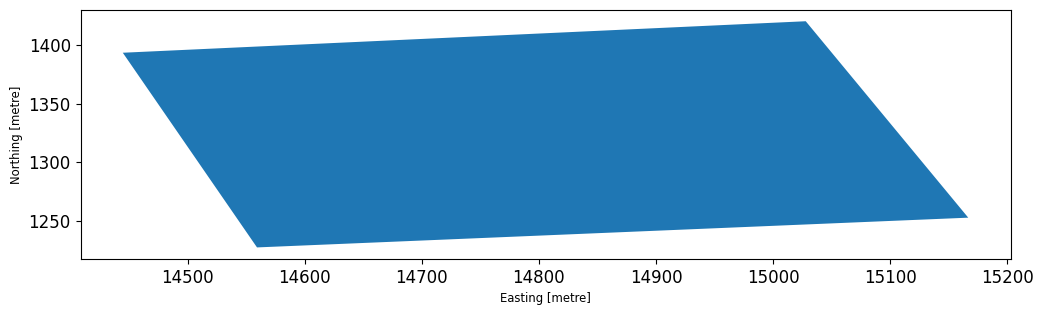

In [ ]:
AOI_POLY = AOI.explode(index_parts=False)
print(len(AOI_POLY), AOI_POLY.geom_type.unique())

# Convert the AOI from geographic to radar coordinates (azimuth y, range x)
AOI_RADAR = psi.geocode(AOI_POLY)
AOI_RADAR.plot()

In [ ]:
psi.compute_ps(AOI_RADAR) # Use of the AOI in radar coordinates

Intensity Normalization:   0%|          | 0/9000000.0 [00:00<?, ?it/s]

Compute Stability Measures:   0%|          | 0/9000000.0 [00:00<?, ?it/s]

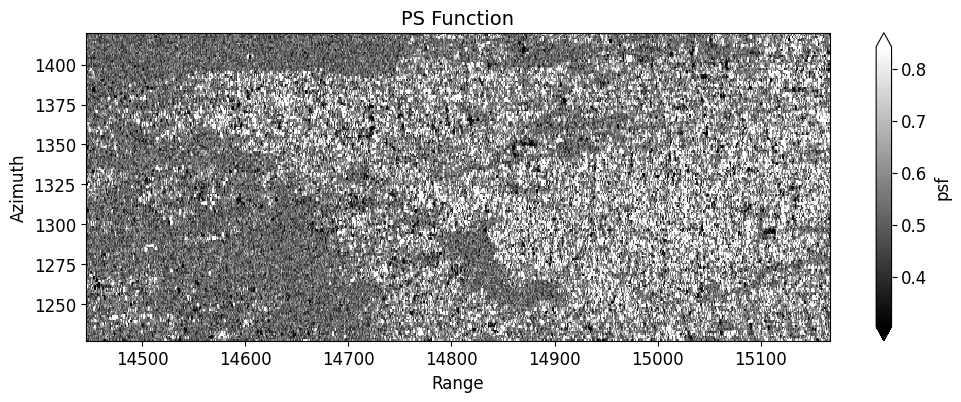

In [ ]:
# PS function: average / (2 * std), the inverse of the amplitude dispersion index
psi.plot_psfunction(quantile=[0.01, 0.90])

## Interferogramas

Genera interferogramas directos

In [ ]:
# Single-look interferograms computed in memory (PyGMTSAR save_stack writes empty files
# with the current Colab xarray/dask versions), following the same steps as compute_interferogram
psf = psi.psfunction()
pairs_all, dates_all = psi.get_pairs(baseline_pairs, dates=True)
w = psf.astype(np.float32).chunk(-1)

data_all = psi.open_data(dates_all).reindex_like(w, fill_value=np.nan)
intensity_look = psi.multilooking(np.square(np.abs(data_all)), wavelength=30)
phasediff = psi.phasediff(pairs_all, data_all, topo='auto')
# 30 m Gaussian filter weighted by psf: correlation estimated from neighbouring stable pixels
phasediff_look = psi.multilooking(phasediff, weight=w, wavelength=30)
corr = psi.correlation(phasediff_look, intensity_look).where(np.isfinite(w))
intf = psi.interferogram(phasediff_look.where(np.isfinite(w)))

ds_ps = xr.merge([intf, corr])
tqdm_dask(ds_ps := ds_ps.persist(), desc='Computing interferograms')
ds_ps = ds_ps.compute()
ds_ps

Computing interferograms:   0%|          | 0/9000000.0 [00:00<?, ?it/s]

INFO:distributed.core:Starting established connection to tcp://127.0.0.1:57694


<xarray.Dataset> Size: 133MB
Dimensions:      (pair: 119, y: 193, x: 722)
Coordinates:
  * pair         (pair) <U21 10kB '2024-10-10 2024-10-22' ... '2026-03-22 202...
    ref          (pair) datetime64[ns] 952B 2024-10-10 2024-10-10 ... 2026-03-22
    rep          (pair) datetime64[ns] 952B 2024-10-22 2024-11-03 ... 2026-04-03
  * y            (y) float64 2kB 1.228e+03 1.228e+03 ... 1.418e+03 1.42e+03
  * x            (x) float64 6kB 1.445e+04 1.445e+04 ... 1.517e+04 1.517e+04
Data variables:
    phase        (pair, y, x) float32 66MB 0.4401 0.4717 ... -2.618 -2.403
    correlation  (pair, y, x) float32 66MB 0.8345 0.7723 0.6019 ... 0.726 0.6701

In [ ]:
INTF_FILE = f'{WORKDIR}/intf_slook_ps.nc'
ds_ps.to_netcdf(INTF_FILE, engine='h5netcdf')

# Check: reopen and count valid pixels per pair
ds_check = xr.open_dataset(INTF_FILE, engine='h5netcdf')
n_valid = np.isfinite(ds_check.phase).sum(['y', 'x'])
print('Pairs with data:', int((n_valid > 0).sum()), 'of', n_valid.size)

Pairs with data: 119 of 119


In [ ]:
ds_ps = xr.open_dataset(INTF_FILE, engine='h5netcdf').load()

## Seleccionar los PS (dispersores persistentes)

PS selected: 7331 of 139346 pixels


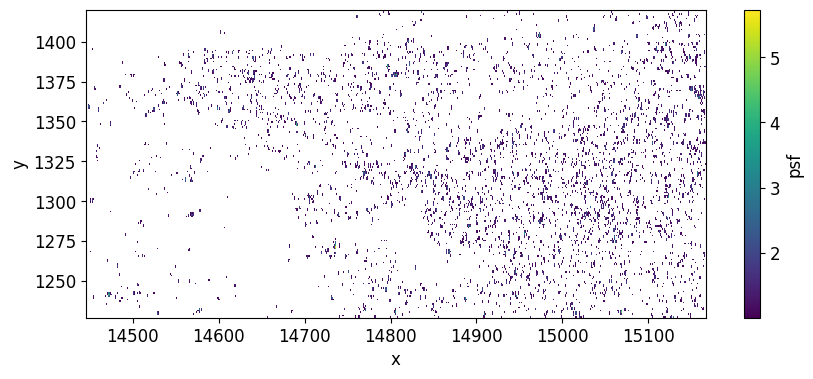

In [ ]:
# psf is computed on intensity: psf ≈ 1 / (4 * D_A), so D_A < 0.25  <=>  psf > 1
PSF_THRESHOLD = 1
ps_mask = (psf > PSF_THRESHOLD).reindex_like(ds_ps.phase.isel(pair=0), fill_value=False)
print('PS selected:', int(ps_mask.sum()), 'of', int(np.isfinite(psf).sum()), 'pixels')

psf.where(ps_mask).plot(cmap='viridis', figsize=(10, 4))

In [ ]:
# Keep only PS pixels as a 1D list of points (stack dimension)
phase_ps = ds_ps.phase.where(ps_mask).stack(stack=['y', 'x']).dropna('stack', how='all')
corr_ps = ds_ps.correlation.where(ps_mask).stack(stack=['y', 'x']).sel(stack=phase_ps['stack'])
print(phase_ps.sizes)

Frozen({'pair': 119, 'stack': 7331})


## Geolocalización de los PS y zona de referencia

Como referencia se usan los PS fuera de las áreas de deformación activa (ADAs) de Vega et al. (2026).

In [ ]:
# Interpolate latitude/longitude of each PS from the inverse geocoding table
trans_inv = psi.get_trans_inv()
ys = xr.DataArray(phase_ps['y'].values, dims='points')
xs = xr.DataArray(phase_ps['x'].values, dims='points')
lat = trans_inv.lt.interp(y=ys, x=xs).compute().values
lon = trans_inv.ll.interp(y=ys, x=xs).compute().values
ps_gdf = gpd.GeoDataFrame(geometry=gpd.points_from_xy(lon, lat), crs=4326)

# ADAs of Manrique (Vega et al., 2026)
adas = gpd.read_file(ADA_FILE).to_crs(4326)
adas_manrique = adas[adas['SECTOR'] == 'Manrique']

# Reference PS: outside the ADAs (~100 m buffer)
active = adas_manrique.buffer(0.001).union_all()
outside = ~ps_gdf.within(active)
print('Reference PS:', int(outside.sum()), 'of', len(ps_gdf))

Reference PS: 5012 of 7331


In [ ]:
# Remove the common phase of the reference PS in each pair (atmosphere, orbits, pair constant)
ref_mask = xr.DataArray(outside.values, dims='stack', coords={'stack': phase_ps['stack']})
z = np.exp(1j * phase_ps)
z_ref = z.where(ref_mask).mean('stack')
z_rel = z * np.conj(z_ref)
phase_ps_ref = np.arctan2(z_rel.imag, z_rel.real).rename('phase')

## Serie de tiempo y velocidad

In [ ]:
# Temporal (1D) unwrapping of each PS along the pair network, weighted by correlation
unwrap_ps = psi.unwrap1d(phase_ps_ref, weight=corr_ps)

# Phase (radians) to line-of-sight displacement (mm) for each pair
disp_pairs_ps = psi.los_displacement_mm(unwrap_ps)

# Least squares: displacement per date for each PS, weighted by correlation
disp_ps = psi.lstsq(disp_pairs_ps, corr_ps)

# Linear LOS velocity (mm/year) for each PS
velocity_ps = psi.velocity(disp_ps).compute()
v = velocity_ps.values
print('Percentiles 1, 5, 25, 50, 75, 95, 99:', np.round(np.nanpercentile(v, [1, 5, 25, 50, 75, 95, 99]), 1))

Note: data chunk size (inf is too large for stack processing
Note: auto tune data chunk size to 1D chunk: (16384)
Note: data chunk size (inf is too large for stack processing
Note: auto tune data chunk size to 1D chunk: (16384)
Percentiles 1, 5, 25, 50, 75, 95, 99: [-22.2  -6.6  -1.9  -0.3   0.7   2.    4.9]


Text(0.5, 1.0, 'PS LOS velocity (mm/yr)')

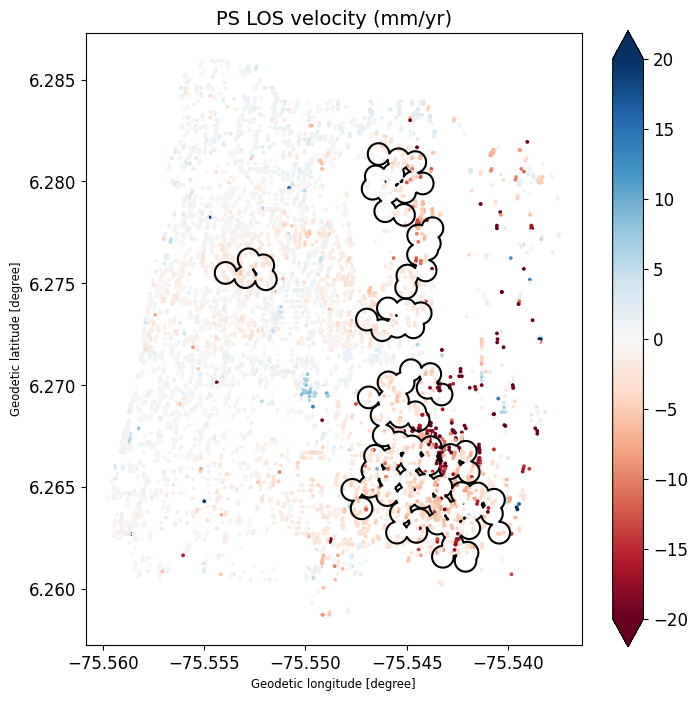

In [ ]:
# Reference velocities to the median of the reference PS
ps_gdf['velocity'] = v - np.nanmedian(v[outside.values])

ax = ps_gdf.plot(column='velocity', cmap='RdBu', vmin=-20, vmax=20,
                 markersize=3, legend=True, figsize=(8, 8))
adas_manrique.boundary.plot(ax=ax, color='k')
ax.set_title('PS LOS velocity (mm/yr)')

## Comparación con las ADAs de Vega et al. (2026)

In [ ]:
ps_in = gpd.sjoin(ps_gdf, adas_manrique[['ADA_ID', 'V_MEAN', 'QI_CLASS', 'geometry']], predicate='within')
cmp = ps_in.groupby('ADA_ID').agg(n_PS=('velocity', 'size'), V_PS_median=('velocity', 'median'),
                                  V_MEAN_Vega=('V_MEAN', 'first'), QI=('QI_CLASS', 'first'))
cmp.round(2)

,n_PS,V_PS_median,V_MEAN_Vega,QI
ADA_ID,,,,
23,149,-1.86,-1.73,1
24,752,-3.95,-2.53,1
26,81,-1.52,-2.20,2
27,103,-2.13,-2.74,1
29,63,-2.67,-2.57,3


In [ ]:
# Export PS for GIS (optional)
ps_gdf.to_file(f'{PROJECT_DIR}/PS_Manrique_{REFERENCE}.gpkg', driver='GPKG')

---
## Uso de herramientas de IA generativa:
En el desarrollo de este tutorial, se hizo uso de Claude Opus 5.5 para diseñar y corregir el código, y para proponer ideas de trabajo.

## Referencias
Vega, J., Aristizábal, E., Ospina, A., Barra, A., & Galve, J. P. (2026). Neighbourhoods in motion: Unveiling the drivers behind structural damage hotspots in Medellín (Colombia). Landslides, 23(7), 1913–1933